In [1]:
import json
import os, sys
import pickle
import datetime
import numpy as np
import ROOT as rt
import math
import pandas as pd

## user define
sys.path.append(".")
sys.path.append("./Utils")
from Plotter import HistStack

Welcome to JupyROOT 6.26/08


In [3]:
import sys
# CHANNEL = sys.argv[1]
# DATE = sys.argv[2]
INPUTDIR = sys.argv[1]
CHANNEL = sys.argv[2]
REGION = sys.argv[3]

DUMP_PKL = True
DRAW_SR = True
RUN_SIDEBAND_MET = True
RUN_SIDEBAND_MASS = True
RUN_SIDEBAND_PT = True
DUMP_SIDEBAND_MET_PKL = True
DUMP_SIDEBAND_MASS_PKL = True
DUMP_SIDEBAND_PT_PKL = True
RUN_BTAG = False
EXPORT_VARIABLE = False

# # for dev
# CHANNEL = 'em'
# DATE = '20230427wp80'
# # INPUTDIR = "/eos/user/h/hkwon/Run2/"+DATE+"/ee/"
# INPUTDIR = '/eos/user/h/hkwon/Run2/Preselection/20230427wp80/Presel'
# # 'Run2/Preselection/${DATE1}/Presel'

# REGION = "SR"

In [4]:
if REGION == 'SR':
    file = 'nested_dic_df.pkl'
if REGION == 'VR':   
    file = 'nested_dic_df_PT.pkl'

with open(INPUTDIR+'/'+CHANNEL+'16pre/'+file, 'rb') as f:
    nested_dic_df = pickle.load(f)
with open(INPUTDIR+'/'+CHANNEL+'16post/'+file, 'rb') as f:
    nested_dic_df1 = pickle.load(f)    

dic_df_all = [nested_dic_df['raw'], nested_dic_df1['raw']]
dic_df_met_u_all = [nested_dic_df['met_u'], nested_dic_df1['met_u']]
dic_df_met_d_all = [nested_dic_df['met_d'], nested_dic_df1['met_d']]

selected_columns = [
#                     'MC1C1_pre', 'H3PP_pre', 'H3TPP_pre', 
                    'pt_lead_pre', 'mass_pre', # by auc rank
                    'MT_pre', 'pt_trail_pre', 'Zpt_pre', 'dRll_pre', 'PuppiMET_pre',
                    'dPhilMET_pre', 'dPhillMET_pre', 'U_pre', 'dPhill_pre', 'MT2_pre',
                    'JZB_pre']

dic_df, dic_df_met_u, dic_df_met_d = [{} for _ in range(3)]

for key in dic_df_all[0]:
    list_raw, list_met_u, list_met_d = [[] for _ in range(3)]
    for i in range(2):
        try:
            list_raw.append(dic_df_all[i][key])
            list_met_u.append(dic_df_met_u_all[i][key])
            list_met_d.append(dic_df_met_d_all[i][key])
        except:
            print("missing:", key)
    dic_df[key]=pd.concat(list_raw, ignore_index=True)
    dic_df_met_u[key]=pd.concat(list_met_u, ignore_index=True)
    dic_df_met_d[key]=pd.concat(list_met_d, ignore_index=True)

dic_nested_shape_sys={}
dic_nested_shape_sys["met_u"]=dic_df_met_u
dic_nested_shape_sys["met_d"]=dic_df_met_d    
    
print(dic_df["TT"].columns)
print(dic_df_met_u["TT"].columns)

Index(['PuppiMET_pre', 'mass_pre', 'pt_lead_pre', 'pt_trail_pre', 'U_pre',
       'JZB_pre', 'dPhill_pre', 'dPhilMET_pre', 'MT_pre', 'MT2_pre', 'Zpt_pre',
       'dRll_pre', 'dPhillMET_pre', 'MET_pre', 'MET_phi_pre',
       'PuppiMET_phi_pre', 'eta_lead_pre', 'eta_trail_pre', 'phi_lead_pre',
       'phi_trail_pre', 'njet_pre', 'nbjetflav_pre', 'genweight_u_pre',
       'genweight_d_pre', 'genweight_pre', 'puweight_pre', 'puweight_u_pre',
       'puweight_d_pre', 'l1prefiring_pre', 'l1prefiring_u_pre',
       'l1prefiring_d_pre', 'effSF_pre', 'effSF_u_pre', 'effSF_d_pre',
       'trigSF_pre', 'trigSF_u_pre', 'trigSF_d_pre', 'topSF_pre',
       'topSF_u_pre', 'topSF_d_pre', 'btagSF_pre', 'pt_mu_pre', 'pt_el_pre',
       'eta_mu_pre', 'eta_el_pre', 'phi_mu_pre', 'phi_el_pre', 'weight',
       'wopu', 'wol1', 'woeff', 'wotop', 'wobsf', 'weightpuweightUp',
       'weightpuweightDown', 'weightl1prefiringUp', 'weightl1prefiringDown',
       'weighteffSFUp', 'weighteffSFDown', 'weighttopSFUp',

In [5]:
ERA = "em16pre"
dic_variable={
    "PuppiMET_pre": [14, 100, 660, "Puppi p_{T}^{miss} [GeV]"],    
    "pt_lead_pre": [15, 80,  660, "p_{T}(l_{lead}) [GeV]"],
    "pt_trail_pre": [15, 40, 520, "p_{T}(l_{trail}) [GeV]"], 
}
list_variables = [(key, dic_variable[key]) for key in dic_variable]
# os.system("mkdir -p "+DATE+"/Presel/"+CHANNEL+"16/SR")

# for variable, r in dic_variable.items():
#     if not "Puppi" in variable:
#         threshold = 0.3
#     else:
#         threshold = 0.5
#     hist=HistStack(dic_df, variable, "weight", r[0], r[1], r[2], r[3])  
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+CHANNEL+"16/SR/norm_", blind_from=threshold) 
# hist.get_yeilds()
# hist.draw_pie(file_name=DATE+"/Presel/"+CHANNEL+"16/SR/pie_")  

In [6]:
import math
# sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF", "met", "scale"]
sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF", "met"]

def draw_with_systematics(dic_df_raw, dic_nested_shape_sys, sys_list, variable, r, region):
    dic_sys = {}
    dic_sys_sqr = {}
    # nominal weight plot
    hist=HistStack(dic_df_raw, variable, 'weight', r[0], r[1], r[2], r[3])            
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+CHANNEL+"16/"+region+"/sys/norm_"+query_str)     
    dic_yields = hist.get_yields_by_bin()
    bkg_norm = dic_yields['bkg']

    for s in sys_list:
        if "met" in s or "scale" in s: # fill later
            continue
        # up
        hist=HistStack(dic_df_raw, variable, 'weight'+s+'Up', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+CHANNEL+"16/"+region+"/sys/systUp_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysUp = dic_yields['bkg']
        dic_sys[s+'Up'] = np.array(sysUp) - np.array(bkg_norm)
        # down
        hist=HistStack(dic_df_raw, variable, 'weight'+s+'Down', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+CHANNEL+"16/"+region+"/sys/systDown_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysDown = dic_yields['bkg']
        dic_sys[s+'Down'] = np.array(sysDown) - np.array(bkg_norm)
    if "el_pre" not in variable and "mu_pre" not in variable and "PuppiMET_phi_pre" not in variable: #temp
        # shape sys
        hist=HistStack(dic_nested_shape_sys['met_u'], variable, 'weightmetUp', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+CHANNEL+"16/"+region+"/sys/systUp_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysUp = dic_yields['bkg']
        dic_sys['metUp'] = np.array(sysUp) - np.array(bkg_norm)
        hist=HistStack(dic_nested_shape_sys['met_d'], variable, 'weightmetDown', r[0], r[1], r[2], r[3])            
        c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+CHANNEL+"16/"+region+"/sys/systUp_"+s+query_str)     
        dic_yields = hist.get_yields_by_bin()
        sysUp = dic_yields['bkg']
        dic_sys['metDown'] = np.array(sysUp) - np.array(bkg_norm)

#     hist=HistStack(dic_nested_shape_sys['scale_u'], variable, 'weightscaleUp', r[0], r[1], r[2], r[3])            
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
#     dic_yields = hist.get_yields_by_bin()
#     sysUp = dic_yields['bkg']
#     dic_sys['scaleUp'] = np.array(sysUp) - np.array(bkg_norm)
#     hist=HistStack(dic_nested_shape_sys['scale_d'], variable, 'weightscaleDown', r[0], r[1], r[2], r[3])            
#     c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/sys/systUp_"+s+query_str)     
#     dic_yields = hist.get_yields_by_bin()
#     sysUp = dic_yields['bkg']
#     dic_sys['scaleDown'] = np.array(sysUp) - np.array(bkg_norm) 
    else:
#         sys_list = ["puweight", "l1prefiring", "effSF", "topSF"]
        sys_list = ["puweight", "l1prefiring", "effSF", "topSF", "trigSF"]
    # si^2
    for s in sys_list:
        # by source
        sqrUp = [x*x if x>0 else -x*x for x in dic_sys[s+'Up']]
        sqrUp_up = [x if x>0 else 0 for x in sqrUp]
        sqrUp_down = [x if x<0 else 0 for x in sqrUp]
        sqrDown = [x*x if x>0 else -x*x for x in dic_sys[s+'Down']]
        sqrDown_up = [x if x>0 else 0 for x in sqrDown]
        sqrDown_down = [x if x<0 else 0 for x in sqrDown]
        
        sqr_up = np.array(sqrUp_up) + np.array(sqrDown_up)
        sqr_down = np.array(sqrUp_down) + np.array(sqrDown_down)
        
        dic_sys_sqr[s+'Up'] = sqr_up
        dic_sys_sqr[s+'Down'] = np.fabs(sqr_down) #store absolute
        
#     print(dic_sys)
#     print(dic_sys_sqr)
    # sqrt(sumi si^2)
    for i, s in enumerate(sys_list):
        if i==0:
            sum_up = dic_sys_sqr[s+'Up'].copy() # be carefull not to use shallow copy
            sum_down = dic_sys_sqr[s+'Down'].copy()
        else:
            sum_up += dic_sys_sqr[s+'Up']
            sum_down += dic_sys_sqr[s+'Down']

    dic_sys_sqr['sum_up'] = np.sqrt(sum_up)
#     print(sum_up)
#     print(sum_down)
    dic_sys_sqr['sum_down'] = np.sqrt(sum_down)
    print(dic_sys_sqr)
            
    return dic_sys_sqr

In [7]:
from multiprocessing import Pool
def wrapper_mp(variable, r):
    
#     sys_list = ["wotop"] # other than 'weight'
#     for sys_key in sys_list:
#         os.system("mkdir -p "+DATE+"/Presel/"+ERA+"/"+sys_key)
#         hist=HistStack(dic_df_raw, variable, sys_key, r[0], r[1], r[2], r[3])            
#         c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+sys_key+"/preselv1_"+query_str, is_dnn=False) 
    os.system("mkdir -p "+DATE+"/Presel/"+CHANNEL+"16/"+region)
    os.system("mkdir -p "+DATE+"/Presel/"+CHANNEL+"16/"+region+"/sys")
#     sys_list1 = ["puweight", "l1prefiring", "effSF", "topSF"]
#     sys_list1 = ["puweight", "l1prefiring", "effSF"]
    # draw plot with syst
    dic_sys_sqr = draw_with_systematics(dic_df, dic_nested_shape_sys, sys_list, variable, dic_variable[variable], region)
    
    print("here", dic_sys_sqr)
    
    hist=HistStack(dic_df, variable, 'weight', r[0], r[1], r[2], r[3], dic_sys=dic_sys_sqr) 
    threshold = 1
    if region=='SR':
        if not 'phi' in variable and not 'eta' in variable:
#         if not 'eta' in variable:
            threshold = 0.3
        if "PuppiMET" in variable:
            threshold = 0.5
        
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+CHANNEL+"16/"+region+"/systall_"+query_str, blind_from=threshold)   
    return None

{'puweightUp': array([1.40915538e+02, 1.87656309e+02, 5.44174459e+01, 2.65795441e+01,
       6.90849443e-02, 2.99537790e+00, 3.82663304e-02, 7.19126870e-01,
       8.50740691e-02, 5.30422022e-02, 2.78475595e-04, 4.31978468e-03,
       3.83477511e-02, 7.18640551e-04, 1.60531564e-02]), 'puweightDown': array([2.44764341e+02, 2.57639631e+02, 7.59463583e+01, 2.87963028e+01,
       3.80801404e-01, 3.59428022e+00, 1.17420666e-01, 9.98066206e-01,
       1.03845863e-01, 8.27460023e-02, 2.50006049e-04, 0.00000000e+00,
       5.26753034e-02, 8.54427227e-05, 2.80767511e-02]), 'l1prefiringUp': array([3.07880626e+03, 8.25474460e+02, 2.00118584e+02, 4.62129537e+01,
       1.04181193e+01, 2.81289242e+00, 7.74491415e-01, 2.45355125e-01,
       7.64380934e-02, 4.28666176e-02, 1.49106691e-02, 5.91281929e-03,
       1.55793012e-03, 4.48414267e-04, 3.59709177e-03]), 'l1prefiringDown': array([3.17858250e+03, 8.51421462e+02, 2.06606874e+02, 4.75827755e+01,
       1.08022367e+01, 2.89431846e+00, 8.05421804e-0

       8.58568501e-01, 3.57308182e-01])}
here {'puweightUp': array([6.81009710e+02, 3.04617020e+01, 3.02560378e+01, 1.65478100e+00,
       1.86330777e+00, 7.04825798e-01, 0.00000000e+00, 7.35267024e-02,
       2.38787894e-01, 6.94285734e-03, 1.10180227e-03, 1.66285146e-02,
       3.46619849e-03, 3.45565557e-04]), 'puweightDown': array([1.04922654e+03, 4.81239560e+01, 2.93575739e+01, 2.03380440e+00,
       3.27255462e+00, 1.01100537e+00, 3.23217696e-02, 4.65154646e-02,
       2.59474953e-01, 6.06028741e-04, 3.62061023e-05, 2.01128477e-02,
       9.82392118e-03, 4.63270659e-03]), 'l1prefiringUp': array([3.96476047e+03, 7.14917538e+02, 1.33530519e+02, 2.90103649e+01,
       6.87061124e+00, 1.78434114e+00, 4.84753928e-01, 1.75618619e-01,
       3.83736288e-02, 1.25318619e-02, 6.96714820e-03, 1.22581936e-03,
       1.97171592e-03, 3.23125024e-03]), 'l1prefiringDown': array([4.10508208e+03, 7.35756819e+02, 1.37014924e+02, 2.97085594e+01,
       7.03723528e+00, 1.82954728e+00, 4.99676879e-01,

       1.48625660e-01, 6.49673226e-02, 4.74043346e-02])}
array('f', [15.707606315612793, 0.053507640957832336, 27.990921020507812, 605.2826538085938, 1365.3179931640625, 12236.2216796875, 40.281654357910156, 26.939115524291992])
test
ERROR in TPDF::Open: Cannot open file:20230427wp80/Presel/em16pre/SR/preselv1_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_lead_prebreakdown.pdf
ERROR in TPDF::Open: Cannot open file:20230427wp80/Presel/em16pre/SR/preselv1_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_lead_pre.pdf


Info in <TCanvas::Print>: pdf file 20230427wp80/Presel/em16/SR/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_trail_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230427wp80/Presel/em16/SR/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_lead_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230427wp80/Presel/em16/SR/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_trail_pre.pdf has been created
Info in <TCanvas::Print>: pdf file 20230427wp80/Presel/em16/SR/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_pt_lead_pre.pdf has been created
Info in <TCanvas::Print>: pdf file 20230427wp80/Presel/em16/SR/sys/norm_mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100_PuppiMET_prebreakdown.pdf has been created
Info in <TCanvas::Print>: pdf file 20230427wp80/Presel/em16/SR/sys/norm_mass_pre

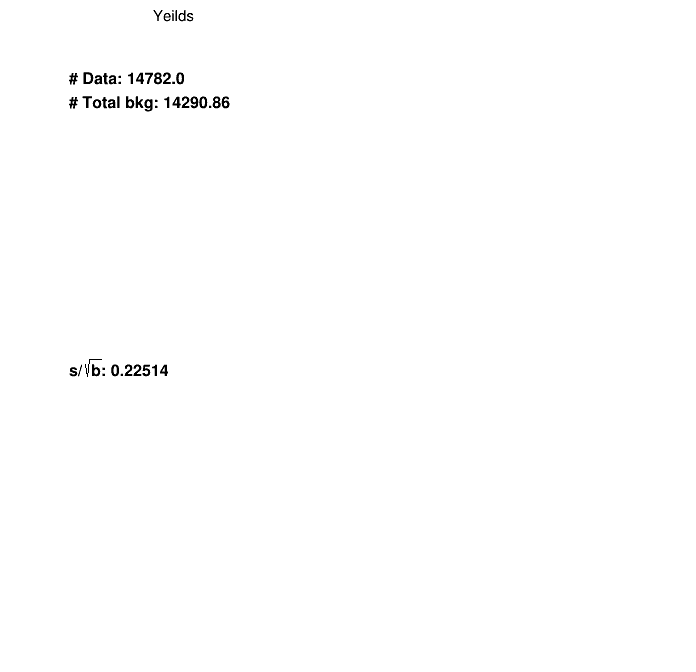

In [9]:
if DRAW_SR:
    region = REGION
    if region == "SR":
        query_str = "mass_pre>100 and pt_lead_pre>80 and pt_trail_pre>40 and PuppiMET_pre>100"
    else:
        query_str = "mass_pre>100 and pt_lead_pre>80 and pt_trail_pre<40 and PuppiMET_pre>100"

    with Pool() as p:
        p.starmap(wrapper_mp, list_variables) 
#     wrapper_mp('mass_pre', [45, 100, 1000, 'M_{ll} [GeV]'])

    # for pie chart
    hist=HistStack(dic_df, "pt_lead_pre", "weight", 31, 80,  660, "p_{T}(l_{lead}) [GeV]") 
    c1=hist.draw_hist("Zp-2500_CH-345", ERA, file_name=DATE+"/Presel/"+ERA+"/"+region+"/preselv1_"+query_str) 
    hist.get_yeilds()
    hist.draw_pie(file_name=DATE+"/Presel/"+CHANNEL+"16/"+region+"/pie_"+query_str)